# NB34 — Focused GeoMAE-ST Ablation & Directional Wind Diagnostics
### Research question: When is GeoMAE-ST preferable *within its ablation family*, and can a better-designed wind representation provide discriminative information?

**Publication integrity**

- This notebook shows a **scoped method-family ablation**, not the ranking of all models evaluated in the thesis.
- LR13 is retained as a *classical reference*. NodeGRU-L14 was evaluated previously (NB20/NB21/NB32), but is **not a member of the GeoMAE component ablation**, so it is intentionally absent from the main method-family visualization. **Its previous results must not be denied or suppressed in a comprehensive benchmark.**
- All main scores are recomputed on identical August cell-day rows from NB31B exports. August is **previously used development data**, not independent held-out evidence.
- Wind indicators constructed here are **diagnostics**, not new trained GeoMAE forecasts. A higher single-feature PR-AUC is **not proof that adding wind improves GeoMAE**.
- Forecast origin `t` uses only data through `t`. Label `target_fire_active_t1` describes hotspot detection at `t+1`; FIRMS hotspot is not verified fire ignition or human action.

**Research hypotheses (defined before looking at the results of this notebook):**

H1. The common "any aligned hotspot nearby" indicator is too prevalent to discriminate Emerging-3 positives.

H2. Restricting potential source cells to hotspot activity in **at least 2 of `t,t-1,t-2`**, then computing a signed **source→target** wind alignment, may give more selective contextual information.

H3. Directional controls (reverse-wind exposure) and no-wind persistent-source exposure should be compared before attributing useful incremental information to wind.

This notebook **does not retune parameters** to maximize August outcome metrics and **does not retrain a model**. It exports a pre-specified plan for a later matched-architecture wind-gating test on genuinely new dates/areas if available.

In [2]:
# 1. Imports
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
from IPython.display import display, Markdown

warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.max_columns', 80)
pd.set_option('display.width', 220)
RNG_SEED = 20261017
N_BOOT = 1500
print('Diagnostic-only notebook: no model training')

Diagnostic-only notebook: no model training


In [3]:
# 2. Locate genuine NB31B outputs and dataset, without overwriting previous results
CANDIDATES = [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent,
              Path('/content/skripsi-karhut'), Path('/content/drive/MyDrive/skripsi-karhut')]
PROJECT_ROOT_OVERRIDE = None  # e.g. Path(r'C:\Users\Asus\Documents\skripsi-karhut')
if PROJECT_ROOT_OVERRIDE is not None:
    CANDIDATES.insert(0, Path(PROJECT_ROOT_OVERRIDE))

NB31_REL = Path('model_results/geomae_controlled_ablation/t2/exports/all_model_august_predictions.csv')
DATA_REL = Path('data/processed/regional_025/karhut_ml_dataset_regional_025.csv')
NB32_REL = Path('model_results/geomae_nb32_diagnostics/t2/exports/nb32_emerging_eligible_with_wind_exposure.csv')
ROOT = next((p for p in CANDIDATES if (p/NB31_REL).exists() and (p/DATA_REL).exists()), None)
if ROOT is None:
    raise FileNotFoundError('NB31B August predictions or regional dataset not found. Run NB31B and set PROJECT_ROOT_OVERRIDE.')
RESULT = ROOT/'model_results/geomae_family_wind_diagnostics/t2'
EX = RESULT/'exports'; FIG = RESULT/'figures'
EX.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
print('Root:',ROOT)
print('NB31B exists:',(ROOT/NB31_REL).exists())
print('NB32 diagnostic available:',(ROOT/NB32_REL).exists())
print('Outputs:', RESULT)

Root: c:\Users\Asus\Documents\skripsi-karhut
NB31B exists: True
NB32 diagnostic available: True
Outputs: c:\Users\Asus\Documents\skripsi-karhut\model_results\geomae_family_wind_diagnostics\t2


In [4]:
# 3. Load and audit strictly matched August rows
raw = pd.read_csv(ROOT/NB31_REL, parse_dates=['date'])
raw['cell_id'] = raw['cell_id'].astype(str)
VARIANTS = ['GeoMAE-T','GeoMAE-ST','GeoMAE-ST-Wind','Transformer-ST-Wind Scratch']
LR_COL = 'LR13 baseline (matched train)'
required = {'date','cell_id','target_fire_active_t1','active_days_prev3_incl_t', LR_COL, *VARIANTS}
missing = sorted(required - set(raw.columns))
if missing: raise ValueError(f'NB31B export columns missing: {missing}')
assert not raw.duplicated(['date','cell_id']).any(), 'Duplicate cell-day comparison keys'
assert raw['date'].between('2026-08-01','2026-08-31').all(), 'NB31B comparison must be August only'
for c in VARIANTS+[LR_COL]:
    assert np.isfinite(raw[c].astype(float).to_numpy()).all(), f'Nonfinite scores: {c}'
raw['y'] = raw['target_fire_active_t1'].astype(int)
assert raw['y'].isin([0,1]).all(), 'Target must be binary'
raw['emerging_eligible'] = raw['active_days_prev3_incl_t'].eq(0)
em = raw.loc[raw['emerging_eligible']].copy()
assert em['y'].sum()>0 and em['y'].nunique()==2
print('August rows:',len(raw),'| Emerging rows:',len(em),'| Emerging positives:',int(em.y.sum()))
print('Emerging prevalence:', round(float(em.y.mean()),4))

August rows: 4123 | Emerging rows: 1241 | Emerging positives: 224
Emerging prevalence: 0.1805


## PART A — Scope-limited forecasting comparison

The figure and table below are a **GeoMAE-family ablation plus matched controls**. They must **not** be published as "all methods attempted". Original NodeGRU-L14 performance remains documented in NB20/NB21/NB32.

**Primary subgroup, by research scope:** Emerging-3 eligible cell-days. **Secondary:** overall and persistent-context performance.

In [5]:
# 4. Recompute August model-family leaderboard from exported per-row predictions
SPEC = [('GeoMAE-ST','GeoMAE-ST'),('GeoMAE-T','GeoMAE-T'),
        ('GeoMAE-ST-Wind','GeoMAE-ST-Wind'),('LR13 (classical reference)',LR_COL),
        ('Transformer-ST-Wind Scratch','Transformer-ST-Wind Scratch')]

def ap(df, col):
    if len(df)==0 or df['y'].sum()==0: return np.nan
    return float(average_precision_score(df['y'], df[col]))

rows=[]
for label,col in SPEC:
    rows.append({'Method':label,'Emerging-3 PR-AUC':ap(em,col),
                 'Overall PR-AUC':ap(raw,col),
                 'Persistent-context PR-AUC':ap(raw.loc[~raw.emerging_eligible],col),
                 'Eligible rows':len(em),'Eligible positives':int(em.y.sum())})
leaderboard=pd.DataFrame(rows).sort_values('Emerging-3 PR-AUC',ascending=False).reset_index(drop=True)
display(leaderboard)
print('Scope: only displayed variants + LR13 reference; NOT comprehensive forecasting ranking.')

,Method,Emerging-3 PR-AUC,Overall PR-AUC,Persistent-context PR-AUC,Eligible rows,Eligible positives
0,GeoMAE-ST,0.322046,0.822513,0.906221,1241,224
1,GeoMAE-T,0.288550,0.836359,0.908297,1241,224
2,GeoMAE-ST-Wind,0.285513,0.766745,0.892775,1241,224
3,LR13 (classical reference),0.276978,0.877614,0.909170,1241,224
4,Transformer-ST-Wind Scratch,0.252851,0.823387,0.906654,1241,224


Scope: only displayed variants + LR13 reference; NOT comprehensive forecasting ranking.


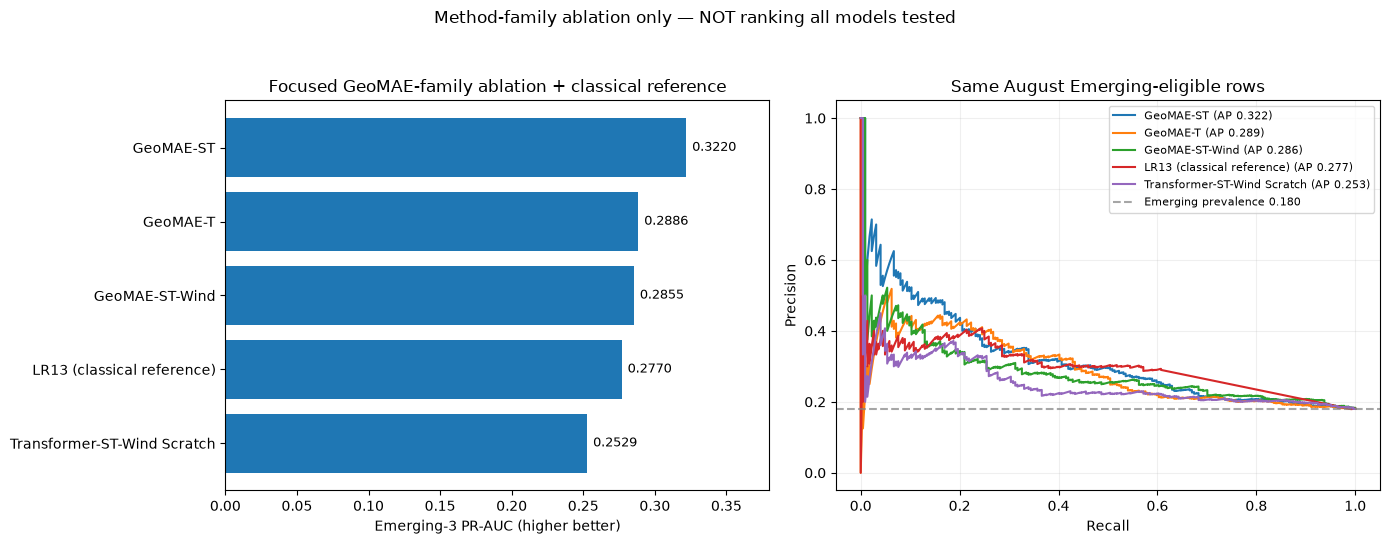

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\geomae_family_wind_diagnostics\t2\figures\01_scoped_geomae_ablation.png


In [6]:
# 5. Plot method-family PR-AUC with truthful caption and subset labels
fig,axes=plt.subplots(1,2,figsize=(14,5.5))
plot_order=leaderboard.iloc[::-1]
axes[0].barh(plot_order['Method'],plot_order['Emerging-3 PR-AUC'])
axes[0].set(xlabel='Emerging-3 PR-AUC (higher better)',
            title='Focused GeoMAE-family ablation + classical reference')
axes[0].set_xlim(0,max(.38,leaderboard['Emerging-3 PR-AUC'].max()*1.13))
for i,val in enumerate(plot_order['Emerging-3 PR-AUC']):
    axes[0].text(val+0.004,i,f'{val:.4f}',va='center',fontsize=9)
for name,col in SPEC:
    p,r,_=precision_recall_curve(em['y'],em[col])
    axes[1].plot(r,p,label=f'{name} (AP {ap(em,col):.3f})')
axes[1].axhline(float(em.y.mean()),ls='--',c='gray',alpha=.7,
                label=f'Emerging prevalence {em.y.mean():.3f}')
axes[1].set(xlabel='Recall',ylabel='Precision',title='Same August Emerging-eligible rows')
axes[1].legend(fontsize=8); axes[1].grid(alpha=.2)
fig.suptitle('Method-family ablation only — NOT ranking all models tested',fontsize=12)
fig.tight_layout(rect=[0,0,1,.94]); path=FIG/'01_scoped_geomae_ablation.png'
fig.savefig(path,dpi=180,bbox_inches='tight');plt.show()
print('Saved:',path)

In [7]:
# 6. Paired block-bootstrap uncertainty: fixed three comparisons
# Resample dates, never individual cell-days as independent units.
comparisons=[('Spatial: ST - T','GeoMAE-T','GeoMAE-ST'),
             ('Wind: ST-Wind - ST','GeoMAE-ST','GeoMAE-ST-Wind'),
             ('ST - LR13 (descriptive; models not matched architecture)',LR_COL,'GeoMAE-ST')]
seed_rng=np.random.default_rng(RNG_SEED)
days=pd.to_datetime(sorted(em['date'].unique()))
blocks=[em.index[em.date.eq(day)].to_numpy() for day in days]
index_to_pos={idx:i for i,idx in enumerate(em.index)}
block_pos=[np.asarray([index_to_pos[i] for i in block],dtype=int) for block in blocks]
y=em.y.to_numpy(dtype=int)
bootstrap=[]
for label,left,right in comparisons:
    left_scores=em[left].to_numpy();right_scores=em[right].to_numpy()
    point=float(average_precision_score(y,right_scores)-average_precision_score(y,left_scores))
    diffs=[]
    for _ in range(N_BOOT):
        chosen=np.concatenate([block_pos[i] for i in seed_rng.integers(0,len(days),len(days))])
        yy=y[chosen]
        if yy.sum()==0 or yy.sum()==len(yy): continue
        diffs.append(float(average_precision_score(yy,right_scores[chosen])-
                           average_precision_score(yy,left_scores[chosen])))
    lo,hi=np.quantile(diffs,[.025,.975])
    bootstrap.append({'Comparison':label,'Emerging Δ PR-AUC':point,
                      'Date-block 95% CI lower':lo,'Date-block 95% CI upper':hi,
                      'Bootstrap samples':len(diffs)})
paired=pd.DataFrame(bootstrap)
display(paired)
print('Previously-used August development period; intervals do not establish independent generalization.')

,Comparison,Emerging Δ PR-AUC,Date-block 95% CI lower,Date-block 95% CI upper,Bootstrap samples
0,Spatial: ST - T,0.033496,-0.007026,0.090610,1500
1,Wind: ST-Wind - ST,-0.036533,-0.078594,-0.002748,1500
2,ST - LR13 (descriptive; models not matched arc...,0.045068,-0.004914,0.097044,1500


Previously-used August development period; intervals do not establish independent generalization.


## PART B — Why the earlier wind representation did not help

NB32's original wind rule used all neighbors within 3 prior dates, and marked a candidate as aligned if **any** positive source-to-target wind alignment was present. This may be insufficiently specific on coarse (0.25°) grid cells, where spatial patterns could reflect broader hotspots and weather reanalysis rather than literal spread.

This diagnostic defines **three hypotheses a priori**:

1. **Persistence gating:** source cell must have hotspot detections on ≥2 of the 3 days `t, t-1, t-2`.
2. **Directional asymmetry:** compare exposure transported **toward** target against opposite-direction exposure.
3. **Exposure normalization:** compare the aligned share of persistent-source exposure, not merely "any aligned source exists".

Wind U/V are used as directional vectors. This does not establish actual fire spread or causality. All features use observations through origin `t` only.

In [8]:
# 7. Read regional source table and verify date-time data availability
reg=pd.read_csv(ROOT/DATA_REL, parse_dates=['date'])
reg['cell_id']=reg['cell_id'].astype(str)
required={'date','cell_id','grid_lat','grid_lon','fire_active','wind_u_mean','wind_v_mean'}
if not required.issubset(reg.columns):
    raise ValueError(f'Regional dataset columns missing: {sorted(required-set(reg.columns))}')
assert not reg.duplicated(['date','cell_id']).any()
reg['lat_key']=reg.grid_lat.round(3)
reg['lon_key']=reg.grid_lon.round(3)
assert not reg.duplicated(['date','lat_key','lon_key']).any()
coords=reg[['cell_id','grid_lat','grid_lon']].drop_duplicates('cell_id')
assert not coords.duplicated('cell_id').any()
if {'grid_lat','grid_lon'}.issubset(em.columns):
    work=em.copy()
    verify=work[['cell_id','grid_lat','grid_lon']].drop_duplicates('cell_id').merge(
        coords,on='cell_id',how='left',validate='one_to_one',suffixes=('_prediction','_source'))
    assert np.allclose(verify.grid_lat_prediction,verify.grid_lat_source)
    assert np.allclose(verify.grid_lon_prediction,verify.grid_lon_source)
else:
    work=em.merge(coords,on='cell_id',how='left',validate='many_to_one')
assert work[['grid_lat','grid_lon']].notna().all().all()
print('Matched Emerging rows with grid centers:',len(work))

Matched Emerging rows with grid centers: 1241


In [9]:
# 8. Vectorized eight-neighbor requests for t,t-1,t-2 source persistence
# Exposure is calculated at forecast origin day t; label is at t+1.
GRID_DEG=.25
DISTANCE_SCALE_KM=50.0  # locked physical-kernel scale; not tuned here
SOURCE_MIN_ACTIVE_DAYS=2
WIND_CALM_EPS=1e-9
reqs=[]
for dx in [-1,0,1]:
    for dy in [-1,0,1]:
        if dx==dy==0: continue
        part=work[['date','cell_id','grid_lat','grid_lon']].copy()
        part['source_lat']=(part.grid_lat+dy*GRID_DEG).round(3)
        part['source_lon']=(part.grid_lon+dx*GRID_DEG).round(3)
        reqs.append(part)
neighbor_req=pd.concat(reqs,ignore_index=True)
src=reg[['date','lat_key','lon_key','fire_active','wind_u_mean','wind_v_mean']].rename(
    columns={'date':'source_date','lat_key':'source_lat','lon_key':'source_lon',
             'fire_active':'source_active','wind_u_mean':'source_u','wind_v_mean':'source_v'})

# Availability at day t: source-day 0/1/2, with no extrapolation of missing source cells.
for lag in [0,1,2]:
    history=src[['source_date','source_lat','source_lon','source_active']].rename(
       columns={'source_active':f'active_lag{lag}'})
    neighbor_req[f'date_lag{lag}']=neighbor_req.date-pd.Timedelta(days=lag)
    neighbor_req=neighbor_req.merge(history, left_on=[f'date_lag{lag}','source_lat','source_lon'],
                                    right_on=['source_date','source_lat','source_lon'],
                                    how='left',validate='many_to_one').drop(columns=['source_date'])
# Need all three observed source-days for robust persistence eligibility.
valid_days=neighbor_req[['active_lag0','active_lag1','active_lag2']].notna().all(axis=1)
neighbor_req['persistent_source']=valid_days & (
    neighbor_req[['active_lag0','active_lag1','active_lag2']].fillna(0).sum(axis=1)
    >=SOURCE_MIN_ACTIVE_DAYS)
neighbor_req['source_active_t']=neighbor_req.active_lag0.fillna(0).astype(float)
# Current t source wind (already observed, no t+1 wind)
neighbor_req=neighbor_req.merge(src[['source_date','source_lat','source_lon','source_u','source_v']],
                 left_on=['date','source_lat','source_lon'],right_on=['source_date','source_lat','source_lon'],
                 how='left',validate='many_to_one').drop(columns=['source_date'])
print('Neighbor candidates:',len(neighbor_req))
print('Persistent source-direction candidates:',int(neighbor_req.persistent_source.sum()))

Neighbor candidates: 9928
Persistent source-direction candidates: 2418


In [10]:
# 9. Source-to-target distance and directional wind exposure
lat_src=neighbor_req.source_lat.to_numpy(float)
lon_src=neighbor_req.source_lon.to_numpy(float)
lat_dst=neighbor_req.grid_lat.to_numpy(float)
lon_dst=neighbor_req.grid_lon.to_numpy(float)
mean_lat=np.radians((lat_src+lat_dst)/2)
east=(lon_dst-lon_src)*111.320*np.cos(mean_lat)
north=(lat_dst-lat_src)*110.574
dist=np.hypot(east,north)
valid_distance=(dist>1e-5)
u=neighbor_req.source_u.fillna(0).to_numpy(float)
v=neighbor_req.source_v.fillna(0).to_numpy(float)
speed=np.hypot(u,v)
cos=np.zeros(len(neighbor_req),dtype=float)
valid_vec=(speed>WIND_CALM_EPS)&valid_distance&np.isfinite(speed)
cos[valid_vec]=(u[valid_vec]*east[valid_vec]+v[valid_vec]*north[valid_vec])/(speed[valid_vec]*dist[valid_vec])
cos=np.clip(cos,-1,1)
proximity=np.exp(-dist/DISTANCE_SCALE_KM)
persistent=neighbor_req.persistent_source.to_numpy(float)
active=neighbor_req.source_active_t.to_numpy(float)
neighbor_req['ordinary_neighbor_exposure'] = active*proximity
neighbor_req['ordinary_upwind_exposure'] = active*proximity*np.maximum(cos,0)
neighbor_req['persistent_proximity_exposure'] = persistent*proximity
neighbor_req['persistent_upwind_exposure'] = persistent*proximity*np.maximum(cos,0)
neighbor_req['persistent_reverse_wind_exposure'] = persistent*proximity*np.maximum(-cos,0)
neighbor_req['persistent_source_count'] = persistent
aggs={name:(name,'sum') for name in [
    'ordinary_neighbor_exposure','ordinary_upwind_exposure',
    'persistent_proximity_exposure','persistent_upwind_exposure',
    'persistent_reverse_wind_exposure','persistent_source_count']}
wind_by_cell=neighbor_req.groupby(['date','cell_id'],as_index=False).agg(**aggs)
wind_by_cell['persistent_upwind_fraction']=(wind_by_cell.persistent_upwind_exposure/
    wind_by_cell.persistent_proximity_exposure.clip(lower=1e-8)).clip(0,1)
wind_by_cell['persistent_direction_balance']=(
    (wind_by_cell.persistent_upwind_exposure-wind_by_cell.persistent_reverse_wind_exposure)/
    (wind_by_cell.persistent_upwind_exposure+wind_by_cell.persistent_reverse_wind_exposure).clip(lower=1e-8))
wind_by_cell['has_persistent_source']=wind_by_cell.persistent_source_count.gt(0)
wind_by_cell['has_any_aligned_neighbor']=wind_by_cell.ordinary_upwind_exposure.gt(0)
wind_by_cell['has_persistent_upwind_source']=wind_by_cell.persistent_upwind_exposure.gt(0)
wind_df=work.merge(wind_by_cell,on=['date','cell_id'],how='left',validate='one_to_one')
assert len(wind_df)==len(work) and not wind_df[['persistent_upwind_exposure','persistent_source_count']].isna().any().any()
print('Analysis cell-days:',len(wind_df))
print('Directly computed from observed source cells; wind is directional context only.')

Analysis cell-days: 1241
Directly computed from observed source cells; wind is directional context only.


In [11]:
# 10. Locked wind feature diagnostic metrics — NO GeoMAE model training
# AP for a single feature is NOT the PR-AUC of a GeoMAE forecasting model.
wind_metrics=[
    ('Any aligned active neighbor (binary)','has_any_aligned_neighbor'),
    ('Nearby activity (no wind)','ordinary_neighbor_exposure'),
    ('Upwind activity (any source)','ordinary_upwind_exposure'),
    ('Persistent source present (no wind)','has_persistent_source'),
    ('Persistent proximity (no wind)','persistent_proximity_exposure'),
    ('Persistent upwind exposure','persistent_upwind_exposure'),
    ('Persistent *reverse-wind* negative control','persistent_reverse_wind_exposure'),
    ('Persistent upwind fraction','persistent_upwind_fraction'),
    ('Persistent upwind-minus-downwind balance','persistent_direction_balance'),
]
metrics=[]
for label,col in wind_metrics:
    scores=wind_df[col].astype(float).to_numpy()
    yy=wind_df.y.to_numpy(dtype=int)
    metrics.append({'Feature':label,'Column':col,'Nonzero share':float((scores>0).mean()),
        'Mean positive':float(np.mean(scores[yy==1])),
        'Mean negative':float(np.mean(scores[yy==0])),
        'Single-feature PR-AUC':float(average_precision_score(yy,scores)),
        'Single-feature ROC-AUC':float(roc_auc_score(yy,scores))})
wind_table=pd.DataFrame(metrics)
display(wind_table)
print('Observed Emerging prevalence:',round(float(wind_df.y.mean()),4))
print('Interpretation: these are standalone feature-ranking diagnostics, not performance gains over GeoMAE-ST.')

,Feature,Column,Nonzero share,Mean positive,Mean negative,Single-feature PR-AUC,Single-feature ROC-AUC
0,Any aligned active neighbor (binary),has_any_aligned_neighbor,0.666398,0.754464,0.647001,0.198496,0.553732
1,Nearby activity (no wind),ordinary_neighbor_exposure,0.827558,1.542793,1.079401,0.277026,0.632748
2,Upwind activity (any source),ordinary_upwind_exposure,0.666398,0.499435,0.357025,0.255196,0.590794
3,Persistent source present (no wind),has_persistent_source,0.786463,0.834821,0.775811,0.189765,0.529505
4,Persistent proximity (no wind),persistent_proximity_exposure,0.786463,1.246237,0.946019,0.246599,0.596118
5,Persistent upwind exposure,persistent_upwind_exposure,0.614021,0.409986,0.314303,0.236021,0.557979
6,Persistent *reverse-wind* negative control,persistent_reverse_wind_exposure,0.543916,0.397425,0.284878,0.228294,0.574051
7,Persistent upwind fraction,persistent_upwind_fraction,0.614021,0.282160,0.277860,0.182994,0.513454
8,Persistent upwind-minus-downwind balance,persistent_direction_balance,0.429492,0.019366,0.079114,0.168253,0.473620


Observed Emerging prevalence: 0.1805
Interpretation: these are standalone feature-ranking diagnostics, not performance gains over GeoMAE-ST.


,Context indicator,Actual t+1 hotspot,Rows,Share indicator true
0,Any upwind active neighbor,0,1017,0.647001
1,Any upwind active neighbor,1,224,0.754464
2,Has persistent source 2/3,0,1017,0.775811
3,Has persistent source 2/3,1,224,0.834821
4,Persistent + wind-aligned source,0,1017,0.605703
5,Persistent + wind-aligned source,1,224,0.651786


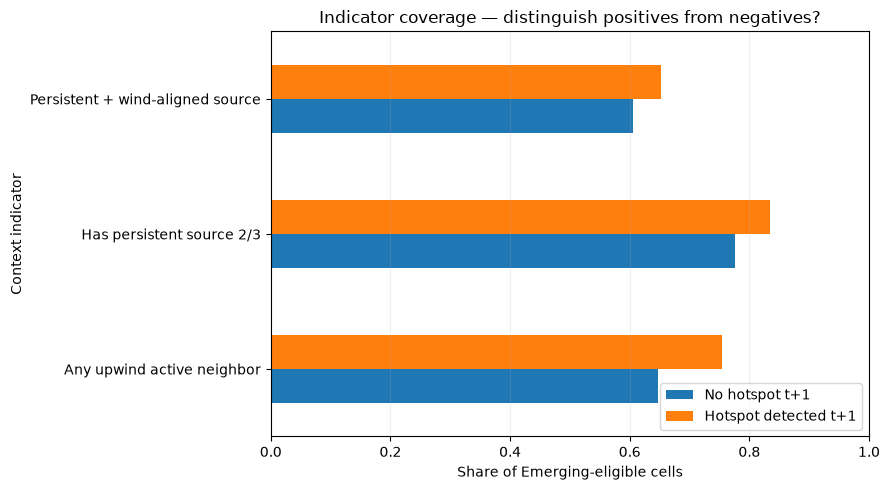

In [12]:
# 11. Discrimination/coverage by outcome: does persistence restrict indiscriminate source matches?
rows=[]
for col,label in [
    ('has_any_aligned_neighbor','Any upwind active neighbor'),
    ('has_persistent_source','Has persistent source 2/3'),
    ('has_persistent_upwind_source','Persistent + wind-aligned source'),
]:
    for outcome in [0,1]:
        sub=wind_df.loc[wind_df.y.eq(outcome)]
        rows.append({'Context indicator':label,'Actual t+1 hotspot':outcome,
                     'Rows':len(sub),'Share indicator true':float(sub[col].mean())})
coverage=pd.DataFrame(rows)
display(coverage)
fig,ax=plt.subplots(figsize=(9,5))
plot=coverage.pivot(index='Context indicator',columns='Actual t+1 hotspot',values='Share indicator true')
plot.plot(kind='barh',ax=ax,rot=0)
ax.set(xlim=(0,1),xlabel='Share of Emerging-eligible cells',title='Indicator coverage — distinguish positives from negatives?')
ax.legend(['No hotspot t+1','Hotspot detected t+1'])
ax.grid(axis='x',alpha=.2)
fig.tight_layout(); p=FIG/'02_wind_coverage_by_outcome.png';fig.savefig(p,dpi=180,bbox_inches='tight');plt.show()

persistent_upwind_exposure single-feature AP: 0.23602
persistent_reverse_wind_exposure single-feature AP: 0.22829
persistent_proximity_exposure single-feature AP: 0.2466


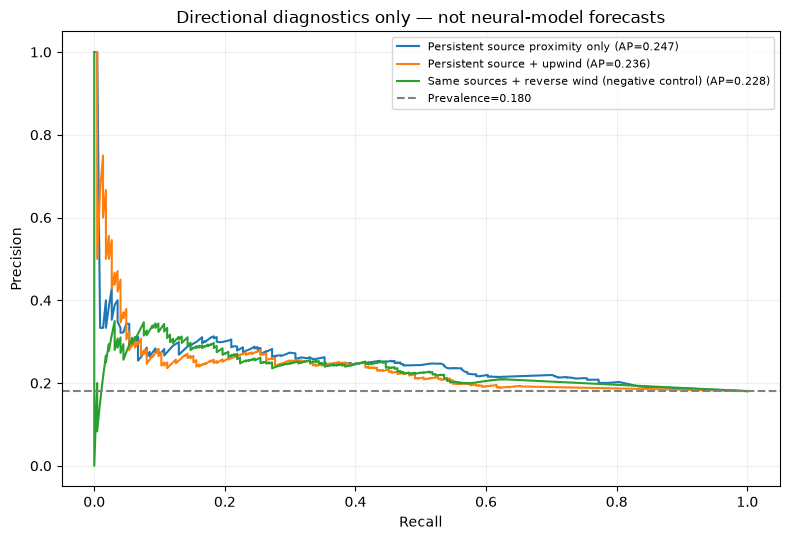

In [13]:
# 12. Directionality check: does upwind information outperform reversed-direction control?
# Exact same persistent sources and distance function; only direction changes.
for name in ['persistent_upwind_exposure','persistent_reverse_wind_exposure','persistent_proximity_exposure']:
    sc=wind_df[name].astype(float).to_numpy()
    print(name, 'single-feature AP:', round(float(average_precision_score(wind_df.y,sc)),5))
fig,ax=plt.subplots(figsize=(8,5.5))
for col,title in [
    ('persistent_proximity_exposure','Persistent source proximity only'),
    ('persistent_upwind_exposure','Persistent source + upwind'),
    ('persistent_reverse_wind_exposure','Same sources + reverse wind (negative control)'),
]:
    pp,rr,_=precision_recall_curve(wind_df.y,wind_df[col])
    ax.plot(rr,pp,label=f'{title} (AP={average_precision_score(wind_df.y,wind_df[col]):.3f})')
ax.axhline(float(wind_df.y.mean()),ls='--',c='gray',label=f'Prevalence={wind_df.y.mean():.3f}')
ax.set(xlabel='Recall',ylabel='Precision',title='Directional diagnostics only — not neural-model forecasts')
ax.legend(fontsize=8);ax.grid(alpha=.2)
fig.tight_layout();p=FIG/'03_wind_diagnostic_pr_curves.png';fig.savefig(p,dpi=180,bbox_inches='tight');plt.show()

In [14]:
# 13. Paired bootstrap of directed vs reversed and proximity-only feature AP
# Diagnostic differences cannot be transferred to the pretrained GeoMAE model.
checks=[('Persistent upwind vs proximity','persistent_proximity_exposure','persistent_upwind_exposure'),
        ('Upwind vs opposite-direction control','persistent_reverse_wind_exposure','persistent_upwind_exposure')]
w_days=pd.to_datetime(sorted(wind_df.date.unique()))
w_blocks=[np.flatnonzero(wind_df.date.eq(d).to_numpy()) for d in w_days]
w_y=wind_df.y.astype(int).to_numpy()
rng=np.random.default_rng(RNG_SEED+1)
check_rows=[]
for label,a,b in checks:
    aa=wind_df[a].astype(float).to_numpy();bb=wind_df[b].astype(float).to_numpy()
    point=float(average_precision_score(w_y,bb)-average_precision_score(w_y,aa))
    values=[]
    for _ in range(N_BOOT):
        ids=np.concatenate([w_blocks[i] for i in rng.integers(0,len(w_days),len(w_days))])
        yy=w_y[ids]
        if yy.sum()==0 or yy.sum()==len(yy): continue
        values.append(float(average_precision_score(yy,bb[ids])-average_precision_score(yy,aa[ids])))
    lo,hi=np.quantile(values,[.025,.975])
    check_rows.append({'Diagnostic test':label,'Δ single-feature AP':point,
                       '95% CI lower':lo,'95% CI upper':hi,'Bootstrap replicates':len(values)})
wind_boot=pd.DataFrame(check_rows)
display(wind_boot)

,Diagnostic test,Δ single-feature AP,95% CI lower,95% CI upper,Bootstrap replicates
0,Persistent upwind vs proximity,-0.010578,-0.034216,0.010998,1500
1,Upwind vs opposite-direction control,0.007727,-0.036990,0.054105,1500


## PART C — What to do if the new directional wind features contain information

A **prospective matched-architecture experiment** can test whether the signal adds to GeoMAE-ST:

| Model | Backbone | Neighbors | Wind integration |
|:--|:--|:--|:--|
| **A. GeoMAE-ST** | same NB24 pretrained encoder | 3×3 | wind channels zeroed, no wind fusion |
| **B. GeoMAE-ST + raw wind** | same | 3×3 | original NB31B raw U/V + unfiltered neighbor exposure |
| **C. GeoMAE-ST + persistence-gated directional wind** | same | 3×3 | source ≥2/3, aligned vs reverse and distance-normalized, learned gate |

Control **identical training origins, hyperparameters, epochs, seeds, normalization (fit on train only), and evaluation rows**. Wind is allowed to help, but **no performance is guaranteed**. Report negative as well as positive outcomes. Do not choose epochs or gate formulation using the already-consumed September results; a truly independent new period/region is best for generalization.

In [15]:
# 14. Optional PyTorch *design blueprint* only; not fitted or evaluated in this notebook.
# A gated residual lets the GeoMAE-ST baseline representation pass through unchanged
# when there is no reliable persistent source. Zero-init residual is a conservative start.
try:
    import torch
    from torch import nn
    class PersistentDirectionalWindGate(nn.Module):
        def __init__(self, hidden_dim, wind_dim=4):
            super().__init__()
            self.gate = nn.Sequential(nn.Linear(wind_dim,16),nn.GELU(),nn.Linear(16,1),nn.Sigmoid())
            self.residual = nn.Sequential(nn.Linear(wind_dim,hidden_dim),nn.Tanh())
            # Start as a no-wind representation; learns a residual only if useful.
            nn.init.zeros_(self.residual[0].weight)
            nn.init.zeros_(self.residual[0].bias)
        def forward(self, st_embedding, wind_context, has_persistent_source):
            confidence = has_persistent_source.to(st_embedding.dtype).reshape(-1,1)
            return st_embedding + confidence*self.gate(wind_context)*self.residual(wind_context)
    print('Wind-gating blueprint class defined (NOT trained, NO performance claim).')
except ImportError:
    print('PyTorch not installed; blueprint skipped. The rest of the notebook does not need torch.')

Wind-gating blueprint class defined (NOT trained, NO performance claim).


In [16]:
# 15. Export all evidence and reproducibility plan
for name,frame in [
    ('nb34_scoped_geomae_family_leaderboard',leaderboard),
    ('nb34_scoped_paired_ablation_bootstrap',paired),
    ('nb34_wind_feature_table',wind_table),
    ('nb34_wind_coverage',coverage),
    ('nb34_wind_directionality_bootstrap',wind_boot),
    ('nb34_emerging_wind_source_features',wind_df),
]:
    frame.to_csv(EX/(name+'.csv'),index=False)
method_lock={
 'dataset':'T2 0.25 degree retained grid cell-days',
 'evaluation':'2026-08-01 through 2026-08-31 previously used development; exploratory',
 'primary_task':'Emerging-3 next-day FIRMS hotspot detection',
 'frozen_source_rule':'At least 2 active days among predictor days t,t-1,t-2',
 'wind_used':'source cell t wind_u_mean,wind_v_mean (towards target), not future wind',
 'distance_weight':'exp(-distance_km/50)',
 'feature_checks':'original, persistent/non-wind, persistent-upwind, reverse-wind, normalized and signed',
 'no_retraining':True,
 'training_needed_for_model_claim':True,
 'comprehensive_baselines_elsewhere':'NodeGRU-L14 was evaluated in NB20/NB21/NB32; omitted ONLY from scoped GeoMAE-family ablation',
 'bootstrap_dates':N_BOOT,
}
(EX/'nb34_methodology_and_scope.json').write_text(json.dumps(method_lock,indent=2),encoding='utf-8')
print('Exports saved:',EX)

Exports saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\geomae_family_wind_diagnostics\t2\exports


In [17]:
# 16. Automatically grounded summary for supervisor
st=float(leaderboard.loc[leaderboard.Method.eq('GeoMAE-ST'),'Emerging-3 PR-AUC'].iloc[0])
t=float(leaderboard.loc[leaderboard.Method.eq('GeoMAE-T'),'Emerging-3 PR-AUC'].iloc[0])
w=float(leaderboard.loc[leaderboard.Method.eq('GeoMAE-ST-Wind'),'Emerging-3 PR-AUC'].iloc[0])
lr=float(leaderboard.loc[leaderboard.Method.eq('LR13 (classical reference)'),'Emerging-3 PR-AUC'].iloc[0])
win_condition=st==float(leaderboard['Emerging-3 PR-AUC'].max())
up_ap=float(wind_table.loc[wind_table.Column.eq('persistent_upwind_exposure'),'Single-feature PR-AUC'].iloc[0])
proximity_ap=float(wind_table.loc[wind_table.Column.eq('persistent_proximity_exposure'),'Single-feature PR-AUC'].iloc[0])
reverse_ap=float(wind_table.loc[wind_table.Column.eq('persistent_reverse_wind_exposure'),'Single-feature PR-AUC'].iloc[0])
summary=f"""# NB34 — Summary for supervisor (August development)

**Scope:** GeoMAE component ablation and classical reference only. Other already-evaluated external benchmarks are not erased; they remain in the broader comparison.

**Matched Emerging-3 PR-AUC:** GeoMAE-T **{t:.4f}**, GeoMAE-ST **{st:.4f}**, GeoMAE-ST-Wind **{w:.4f}**, LR13 **{lr:.4f}**.

**Scoped conclusion:** {'GeoMAE-ST leads the displayed ablation/control set.' if win_condition else 'GeoMAE-ST does not lead the displayed set.'} Within-family spatial difference ST-T is **{st-t:+.4f}**. Original wind difference ST-Wind - ST is **{w-st:+.4f}**.

**Why revisit wind?** Existing "any-aligned-neighbor" exposure has high coverage. Coarse 0.25° cells and three-day source aggregation can dilute directional relevance. The new features gate to ≥2/3 active source days and compare upwind with an opposite-direction control.

**New wind features are NOT trained GeoMAE forecasts:** Persistent proximity-only single-feature AP **{proximity_ap:.4f}**, upwind AP **{up_ap:.4f}**, reversed-wind AP **{reverse_ap:.4f}**. Their comparison only tests feature-level association on previously used August data.

**Next step:** If directional features show a plausible incremental signal, test a 3-variant **matched end-to-end fine-tuning experiment**, freeze choices on training/internal validation, and evaluate on an actually new period/region. Do not assert wind or GeoMAE globally wins until supported by results.
"""
(RESULT/'NB34_supervisor_summary.md').write_text(summary,encoding='utf-8')
display(Markdown(summary))
print('Saved:',RESULT/'NB34_supervisor_summary.md')

# NB34 — Summary for supervisor (August development)

**Scope:** GeoMAE component ablation and classical reference only. Other already-evaluated external benchmarks are not erased; they remain in the broader comparison.

**Matched Emerging-3 PR-AUC:** GeoMAE-T **0.2886**, GeoMAE-ST **0.3220**, GeoMAE-ST-Wind **0.2855**, LR13 **0.2770**.

**Scoped conclusion:** GeoMAE-ST leads the displayed ablation/control set. Within-family spatial difference ST-T is **+0.0335**. Original wind difference ST-Wind - ST is **-0.0365**.

**Why revisit wind?** Existing "any-aligned-neighbor" exposure has high coverage. Coarse 0.25° cells and three-day source aggregation can dilute directional relevance. The new features gate to ≥2/3 active source days and compare upwind with an opposite-direction control.

**New wind features are NOT trained GeoMAE forecasts:** Persistent proximity-only single-feature AP **0.2466**, upwind AP **0.2360**, reversed-wind AP **0.2283**. Their comparison only tests feature-level association on previously used August data.

**Next step:** If directional features show a plausible incremental signal, test a 3-variant **matched end-to-end fine-tuning experiment**, freeze choices on training/internal validation, and evaluate on an actually new period/region. Do not assert wind or GeoMAE globally wins until supported by results.


Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\geomae_family_wind_diagnostics\t2\NB34_supervisor_summary.md


## Research limitations and next actions

1. **No test-set laundering.** August and September have both been observed and influenced development. Use their results as post-development analysis. For out-of-sample superiority, secure a new untouched date/area.
2. **Incomplete ablation of pretraining.** Removing wind channels *at fine-tuning time* from a wind-pretrained checkpoint does not establish benefit of re-pretraining without wind. For a fully isolated factor, retrain identical masked-pretraining tasks with matching input modality.
3. **Wind not causation.** ERA5-like weather is broad-scale environmental context; hotspot grid centers are not ignition sites, and upwind neighbor correlation does not prove fire spread.
4. **No verified anomaly labels.** A near persistent source is not a confirmed false positive; an isolated robust candidate is a priority for investigation, not a confirmed unusual ignition.
5. **If direct wind gating helps:** report all model variants and CIs, not just one favorable configuration. If it does not, keep wind in post-hoc contextual refinement rather than forcing it into forecasting.